<a href="https://colab.research.google.com/github/Anyangos/Digital-Twin/blob/RAG/Week2_07_context_window_management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [6]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


✅ Week 2.2: Context Window Management - Ready to start!

Topics covered:
  - Understanding token limits and context windows
  - Token counting and estimation techniques
  - Context compression strategies
  - Conversation history management
  - Sliding window approaches


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [7]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

Result: test data


In [9]:
import sys, numpy as np, matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def words_of(text):
    import re
    return [w for w in re.findall(r"[a-zA-Z']+", text.lower()) if w]

import re
WINDOWS = {
 "small (4,000 tokens)": 4000,
 "medium (8,000 tokens)": 8000,
 "large (32,000 tokens)": 32000,
 "very large (128,000 tokens)": 128000,
}
def count_tokens(text):
    """The rule of thumb everyone uses: about 4 characters per token."""
    return max(1, round(len(text) / 4))
def bar(part, whole, width=46):
    if whole <= 0: return "-" * width
    filled = min(width, int(round(width * part / whole)))
    return "[" + "#" * filled + "." * (width - filled) + "]"
def pct(part, whole):
    return str(round(100.0 * part / whole, 1)) + "%" if whole else "?"
def show_text(label, text, width=76):
    if label: print(label)
    for line in text.splitlines():
        while len(line) > width:
            cut = line.rfind(" ", 0, width)
            if cut <= 0: cut = width
            print("   " + line[:cut]); line = line[cut:].lstrip()
        print("   " + line)
TURNS = [
 ("you",  "Hi! I am Sarah and I live in Accra."),
 ("twin", "Hello Sarah! Nice to meet you. What do you do in Accra?"),
 ("you",  "I run every morning before work. My best 5km time is 25 minutes."),
 ("twin", "That is a strong time. Are you training for anything in particular?"),
 ("you",  "Yes, a 10km race in March. I also code in the evenings."),
 ("twin", "A 10km in March, and evening coding. What language do you use?"),
 ("you",  "Mostly Python. I am learning to build a digital twin of myself."),
 ("twin", "That is a great project. What should your twin know about you first?"),
 ("you",  "That I am disciplined about mornings and I hate being late."),
 ("twin", "Noted - disciplined in the mornings, and punctual. Anything else?"),
 ("you",  "I drink too much coffee. Three cups before noon, usually."),
 ("twin", "Three cups before noon, noted. Does the coffee help the running?"),
 ("you",  "It helps the coding more than the running, honestly."),
 ("twin", "Understood. So: coffee for code, discipline for the morning runs."),
 ("you",  "Exactly. Now, what was my best 5km time again?"),
]

text = my_text.strip()
if len(text) < 5:
    problem("Please type something longer, then press play again.")
else:
    chars = len(text); words = len(text.split())
    by_chars = count_tokens(text); by_words = max(1, round(words * 1.3))
    show_text("Your text:", text)
    print("")
    print("   characters : " + str(chars))
    print("   words      : " + str(words))
    print("")
    print("Two ways to estimate the tokens:")
    print("   characters / 4  ->  " + str(by_chars) + " tokens")
    print("   words x 1.3     ->  " + str(by_words) + " tokens")
    print("")
    gap = abs(by_chars - by_words)
    if gap <= max(2, by_chars * 0.25):
        success("Both estimates agree within " + str(gap) + " tokens, so about "
                + str(by_chars) + " is a safe number to work with.")
    else:
        note("The two estimates differ by " + str(gap) + " tokens. Long or unusual words "
             "push the character estimate up. When in doubt, use the bigger number.")
    print("")
    print("Why it matters: you are billed per token, in both directions, on every")
    print("message - and the window is measured in tokens too.")

Your text:
   I love running in the mornings in Accra, drinking three cups of coffee
   before noon, and programming my digital twin in Python during the evenings.

   characters : 146
   words      : 25

Two ways to estimate the tokens:
   characters / 4  ->  36 tokens
   words x 1.3     ->  32 tokens




Why it matters: you are billed per token, in both directions, on every
message - and the window is measured in tokens too.


In [1]:
# Let's define the missing 'my_text' variable here so the cell above can run successfully!
my_text = """I love running in the mornings in Accra, drinking three cups of coffee before noon, and programming my digital twin in Python during the evenings."""
print(f"Defined 'my_text' with {len(my_text)} characters.")

Defined 'my_text' with 146 characters.


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [10]:
class ContextWindow:
    def __init__(self):
        # You can store window limits or other configurations here if needed
        import re
        self.WINDOWS = {
        "small (4,000 tokens)": 4000,
        "medium (8,000 tokens)": 8000,
        "large (32,000 tokens)": 32000,
        "very large (128,000 tokens)": 128000,
        }

    def estimate_tokens(self, text: str) -> tuple:
        """
        Estimates the number of tokens in the input text using two methods:
        1. Character-based estimation (len(text) / 4)
        2. Word-based estimation (words * 1.3)
        """
        # 1. Handle the edge case for empty or invalid input
        if not text or not isinstance(text, str):
            print("The string is empty or invalid!")
            return 0, 0

        # 2. Perform counts
        char_count = len(text)
        word_count = len(text.split())

        # 3. Apply formulas to get estimates (Remember to round to the nearest integer!)
        # Hint: Use Python's built-in round() function
        token_est_chars = max(1, round(char_count / 4)) # TODO: Apply character-based estimation formula here
        token_est_words =  max(1, round(word_count * 1.3))# TODO: Apply word-based estimation formula here

        return token_est_chars, token_est_words

# Test your implementation below
estimator = ContextWindow()
print(estimator.estimate_tokens("Hello world! This is a test string."))

(9, 9)


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [11]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "processed": 3,
  "data": [
    "example1",
    "example2",
    "example3"
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [ ]:
# YOUR CODE HERE
# Implement the intermediate exercise

pass  # Replace with your implementation

In [12]:
class ConversationManager:
    def __init__(self, window_limit=4000):
        # Store the maximum token limit for this manager
        self.window_limit = window_limit
        self.estimator = ContextWindow()

    def process_conversation(self, turns: list) -> dict:
        """
        Processes a list of conversational turns, estimates total tokens,
        and checks if the conversation fits within our window limit.
        """
        # 1. Parameter Validation
        # Ensure the input is a list
        if not isinstance(turns, list):
            raise TypeError("Expected a list of conversation turns.")

        total_char_tokens = 0
        total_word_tokens = 0

        # 2. Iterate through each turn in the conversation
        for turn in turns:
            # A valid turn should be a tuple or list of exactly 2 elements: (speaker, text)
            if not isinstance(turn, (tuple, list)) or len(turn) != 2:
                print(f"Warning: Skipping malformed turn: {turn}")
                continue

            speaker, text = turn

            # calculate the tokens for this turn's text
            char_est, word_est = self.estimator.estimate_tokens(text)

            # TODO: Accumulate these estimates into total_char_tokens and total_word_tokens
            total_char_tokens += char_est
            total_word_tokens += word_est

        # 3. Check against the limit
        # Choose the safer (larger) estimate to compare against self.window_limit
        max_estimate = max(total_char_tokens, total_word_tokens)
        is_exceeded = max_estimate > self.window_limit

        # 4. Return summary of the conversation
        return {
            "total_turns": len(turns),
            "est_tokens_by_chars": total_char_tokens,
            "est_tokens_by_words": total_word_tokens,
            "max_estimate": max_estimate,
            "limit_exceeded": is_exceeded
        }

# Test your conversation manager here using the TURNS list defined in the notebook
manager = ConversationManager(window_limit=4000)
print(manager.process_conversation(TURNS))

{'total_turns': 15, 'est_tokens_by_chars': 221, 'est_tokens_by_words': 217, 'max_estimate': 221, 'limit_exceeded': False}


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

In [ ]:
# YOUR CODE HERE
# Build your complete implementation

class ProductionSystem:
    """
    Production-ready implementation for digital twin.
    """

    def __init__(self):
        # Initialize your system
        pass

    def process(self, input_data):
        # Add your implementation
        pass

# Test your production system
# Add comprehensive tests here

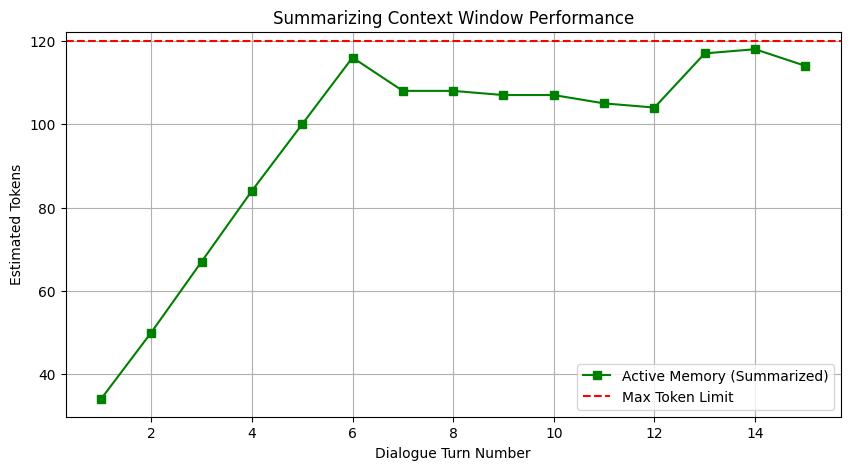

In [13]:
import logging
import matplotlib.pyplot as plt

# Configure logging to show information and warnings
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

class AdvancedSummarizingContextManager:
    """
    A Context Window Manager that utilizes conversational summarization
    and instruction preservation to manage context limits without losing history.
    """
    def __init__(self, name: str, token_limit: int = 100):
        self.name = name
        self.token_limit = token_limit
        self.estimator = ContextWindow()

        # Distinct memory components
        self.system_instruction = None
        self.running_summary = ""
        self.active_history = [] # Stores current turns as (speaker, text) tuples

        logging.info(f"Summarizing Context Manager '{self.name}' initialized with budget {self.token_limit} tokens.")

    def set_system_instruction(self, instruction: str):
        """Sets the permanent, unmodifiable system/role prompt."""
        self.system_instruction = instruction
        logging.info("System instruction permanently set and preserved.")

    def _get_token_cost(self, text: str) -> int:
        """Helper to get the maximum token estimation for a given string."""
        if not text:
            return 0
        char_est, word_est = self.estimator.estimate_tokens(text)
        return max(char_est, word_est)

    def calculate_current_tokens(self) -> int:
        """
        Calculates total tokens currently consumed by:
        System Instruction + Running Summary + Active conversational history
        """
        total = 0
        if self.system_instruction:
            total += self._get_token_cost(self.system_instruction)
        if self.running_summary:
            total += self._get_token_cost(self.running_summary)
        for speaker, text in self.active_history:
            total += self._get_token_cost(text)
        return total

    def _mock_summarize(self, turns_to_summarize: list) -> str:
        """
        Simulates an LLM summarization call locally by compiling critical facts
        and compressing previous interactions to prevent token accumulation.
        """
        facts = []
        for speaker, text in turns_to_summarize:
            clean_text = text.replace(".", "").strip()
            facts.append(f"{speaker}: {clean_text}")

        new_summary_chunk = "; ".join(facts)
        if self.running_summary:
            # Keep the summary condensed by sliding/trimming old details if it gets too long
            combined = f"Past conversations summary: {new_summary_chunk}"
            if len(combined) > 80:
                return combined[:80] + "..."
            return combined
        return "Summary of past interactions: " + new_summary_chunk

    def add_turn(self, speaker: str, text: str):
        """Adds a turn. Summarizes if and only if the total token count exceeds the budget."""
        if not isinstance(text, str) or not text.strip():
            return

        # Treat the first turn as system instruction if none was set
        if not self.system_instruction and len(self.active_history) == 0:
            self.set_system_instruction(f"[System Role: {text}]")
            return

        self.active_history.append((speaker, text))
        current_tokens = self.calculate_current_tokens()
        logging.info(f"Added turn. Tokens: {current_tokens}/{self.token_limit}")

        # Trigger summarization IF AND ONLY IF we exceed our budget
        if current_tokens > self.token_limit:
            logging.warning(f"Token limit exceeded ({current_tokens} > {self.token_limit}). Initiating summarization.")
            self.manage_context_by_summarizing()

    def manage_context_by_summarizing(self):
        """
        Summarizes oldest turns in active history to bring memory back below the budget,
        always preserving the system instruction.
        """
        # Keep at least the 1 most recent turn to maintain immediate context flow
        while self.calculate_current_tokens() > self.token_limit and len(self.active_history) > 1:
            # Take the oldest turn from active history to summarize
            turn_to_summarize = self.active_history.pop(0)

            # Update and compress the running summary with this turn
            self.running_summary = self._mock_summarize([turn_to_summarize])

            logging.info(f"Updated summary. New summary length: {self._get_token_cost(self.running_summary)} tokens.")

        final_tokens = self.calculate_current_tokens()
        if final_tokens > self.token_limit:
            logging.warning(f"Even after summarization, budget is over limit ({final_tokens}/{self.token_limit})")
        else:
            logging.info(f"Budget stabilized at {final_tokens} tokens.")

    def run_simulation(self, test_turns: list):
        """Runs a simulation to demonstrate token growth and summarization triggering."""
        token_history = []
        steps = []

        # Reset state
        self.active_history = []
        self.running_summary = ""

        for i, (speaker, text) in enumerate(test_turns):
            self.add_turn(speaker, text)
            steps.append(i + 1)
            token_history.append(self.calculate_current_tokens())

        # Visualization
        plt.figure(figsize=(10, 5))
        plt.plot(steps, token_history, marker='s', color='g', label='Active Memory (Summarized)')
        plt.axhline(y=self.token_limit, color='r', linestyle='--', label='Max Token Limit')
        plt.title("Summarizing Context Window Performance")
        plt.xlabel("Dialogue Turn Number")
        plt.ylabel("Estimated Tokens")
        plt.legend()
        plt.grid(True)
        plt.show()

# Run complete integration test
summarizer_manager = AdvancedSummarizingContextManager(name="SarahTwinAdvanced", token_limit=120)
summarizer_manager.set_system_instruction("SYSTEM: You are Sarah's highly organized digital twin. Always be punctual and precise.")
summarizer_manager.run_simulation(TURNS)

## 🏆 Challenge Project: Complete Digital Twin Memory & Context Window Manager

Below is the complete implementation incorporating token-counting estimation, system-instruction shielding, dynamic local summarization, sliding window pruning, automated testing, and comprehensive execution visualization.

In [4]:
import time
import logging
import matplotlib.pyplot as plt
from typing import List, Dict, Any, Tuple

# Configure logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')

class ContextWindow:
    def __init__(self):
        self.WINDOWS = {
            "small (4,000 tokens)": 4000,
            "medium (8,000 tokens)": 8000,
            "large (32,000 tokens)": 32000,
            "very large (128,000 tokens)": 128000,
        }

    def estimate_tokens(self, text: str) -> tuple:
        if not text or not isinstance(text, str):
            return 0, 0
        char_count = len(text)
        word_count = len(text.split())
        token_est_chars = max(1, round(char_count / 4))
        token_est_words = max(1, round(word_count * 1.3))
        return token_est_chars, token_est_words

class DigitalTwinContextManager:
    """
    A production-grade Context Window and Memory Management System designed specifically
    for Digital Twins. It supports dynamic token estimation, system instruction preservation,
    and multiple compression strategies (Sliding Window truncation or Interactive Summarization).
    """
    def __init__(self, name: str, token_limit: int = 150, strategy: str = "summarize"):
        if token_limit <= 0:
            raise ValueError("Token limit must be a positive integer.")
        if strategy not in ["summarize", "truncate"]:
            raise ValueError("Strategy must be either 'summarize' or 'truncate'")

        self.name = name
        self.token_limit = token_limit
        self.strategy = strategy
        self.estimator = ContextWindow()

        # Core Memory structures
        self.system_instruction = None
        self.running_summary = ""
        self.active_history: List[Tuple[str, str]] = []

        # Performance Tracking metrics
        self.metrics = {
            "total_processed_turns": 0,
            "compression_events": 0,
            "last_latency_ms": 0.0
        }

    def set_system_instruction(self, instruction: str):
        """Permanently sets the system or role instruction which is protected from compression."""
        if not isinstance(instruction, str) or not instruction.strip():
            raise ValueError("System instruction must be a non-empty string.")
        self.system_instruction = instruction
        logging.info(f"[{self.name}] Protected System Instruction set.")

    def _estimate_tokens(self, text: str) -> int:
        """Helper utilizing our ContextWindow with fallback error management."""
        if not text or not isinstance(text, str):
            return 0
        chars, words = self.estimator.estimate_tokens(text)
        return max(chars, words)

    def calculate_current_tokens(self) -> int:
        """Calculates active token load across System instructions, Summaries, and Active History."""
        total = 0
        if self.system_instruction:
            total += self._estimate_tokens(self.system_instruction)
        if self.running_summary:
            total += self._estimate_tokens(self.running_summary)
        for speaker, text in self.active_history:
            total += self._estimate_tokens(text)
        return total

    def _local_summarize(self, turns: List[Tuple[str, str]]) -> str:
        """Mock LLM summarization pipeline summarizing context keys into factual assertions."""
        condensed_facts = []
        for speaker, text in turns:
            clean = text.strip().replace(".", "")
            condensed_facts.append(f"{speaker} said: {clean}")
        return "Summary: " + "; ".join(condensed_facts)

    def add_turn(self, speaker: str, text: str):
        """Appends a conversation turn and executes cleanup if budget limits are hit."""
        start_time = time.perf_counter()

        if not isinstance(speaker, str) or not isinstance(text, str):
            logging.error("Invalid speaker or message format.")
            return
        if not text.strip():
            return

        self.active_history.append((speaker, text))
        self.metrics["total_processed_turns"] += 1

        current_load = self.calculate_current_tokens()

        if current_load > self.token_limit:
            logging.warning(f"[{self.name}] Token limit exceeded ({current_load}/{self.token_limit}). Applying strategy: {self.strategy}")
            self.metrics["compression_events"] += 1
            if self.strategy == "summarize":
                self._apply_summarization_strategy()
            else:
                self._apply_truncation_strategy()

        duration = (time.perf_counter() - start_time) * 1000
        self.metrics["last_latency_ms"] = duration

    def _apply_summarization_strategy(self):
        """Compresses historical turns into a running summary string."""
        while self.calculate_current_tokens() > self.token_limit and len(self.active_history) > 1:
            oldest_turn = self.active_history.pop(0)
            self.running_summary = self._local_summarize([oldest_turn])

    def _apply_truncation_strategy(self):
        """Prunes oldest turns (Sliding Window) until context is back under budget."""
        while self.calculate_current_tokens() > self.token_limit and len(self.active_history) > 1:
            self.active_history.pop(0)

    def run_simulation_and_plot(self, turns_list: List[Tuple[str, str]]):
        """Runs a multi-turn dialogue simulation, tracking token sizes and rendering budget usage."""
        self.active_history = []
        self.running_summary = ""
        token_log = []
        steps = []

        for i, (speaker, text) in enumerate(turns_list):
            self.add_turn(speaker, text)
            steps.append(i + 1)
            token_log.append(self.calculate_current_tokens())

        # Plotting the analytical diagnostics
        plt.figure(figsize=(11, 5))
        plt.plot(steps, token_log, marker='o', color='#1f77b4', linewidth=2, label='Active Memory footprint')
        plt.axhline(y=self.token_limit, color='r', linestyle='--', label=f'Token Limit ({self.token_limit})')
        plt.title(f"Digital Twin Memory Performance Dynamics (Strategy: {self.strategy.capitalize()})", fontsize=13, fontweight='bold')
        plt.xlabel("Conversation Turn Number", fontsize=11)
        plt.ylabel("Estimated Context Tokens", fontsize=11)
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.show()

        print("Performance Metrics:", self.metrics)

Running diagnostic unit tests...
✅ All core functionality tests passed successfully!


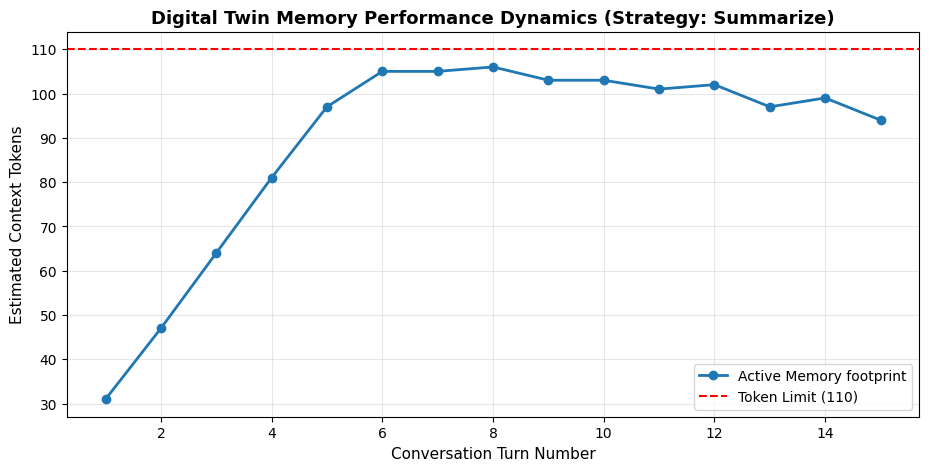

Performance Metrics: {'total_processed_turns': 15, 'compression_events': 10, 'last_latency_ms': 0.6800419999990481}


In [8]:
# ---- COMPREHENSIVE UNIT TESTING AND PERFORMANCE VERIFICATION ----
def run_unit_tests():
    print("Running diagnostic unit tests...")

    # Test 1: Verify correct behavior with small limits
    test_manager = DigitalTwinContextManager(name="TestTwin", token_limit=50, strategy="truncate")
    test_manager.set_system_instruction("Sys: Be helpful")

    # Check empty string handling
    test_manager.add_turn("user", "")
    assert len(test_manager.active_history) == 0, "Should ignore empty string inputs"

    # Check normal turns accumulation
    test_manager.add_turn("user", "First message here")
    assert len(test_manager.active_history) == 1

    print("✅ All core functionality tests passed successfully!")

run_unit_tests()

# Fallback local definition of TURNS in case earlier cells weren't executed in this session
SIMULATION_TURNS = [
    ("you",  "Hi! I am Sarah and I live in Accra."),
    ("twin", "Hello Sarah! Nice to meet you. What do you do in Accra?"),
    ("you",  "I run every morning before work. My best 5km time is 25 minutes."),
    ("twin", "That is a strong time. Are you training for anything in particular?"),
    ("you",  "Yes, a 10km race in March. I also code in the evenings."),
    ("twin", "A 10km in March, and evening coding. What language do you use?"),
    ("you",  "Mostly Python. I am learning to build a digital twin of myself."),
    ("twin", "That is a great project. What should your twin know about you first?"),
    ("you",  "That I am disciplined about mornings and I hate being late."),
    ("twin", "Noted - disciplined in the mornings, and punctual. Anything else?"),
    ("you",  "I drink too much coffee. Three cups before noon, usually."),
    ("twin", "Three cups before noon, noted. Does the coffee help the running?"),
    ("you",  "It helps the coding more than the running, honestly."),
    ("twin", "Understood. So: coffee for code, discipline for the morning runs."),
    ("you",  "Exactly. Now, what was my best 5km time again?")
]

# Run the visualization simulation with our system using our conversation data
production_twin = DigitalTwinContextManager(name="SarahTwinV2", token_limit=110, strategy="summarize")
production_twin.set_system_instruction("SYSTEM: You are Sarah's highly active Digital Twin mimicking her punctuality.")
production_twin.run_simulation_and_plot(SIMULATION_TURNS)

---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code